# 01 — The paper's datasets, and what DHT does with them

**Paper:** Meng et al., *Sample-Based Dynamic Hierarchical Transformer with Layer and Head
Flexibility via Contextual Bandit* (PES 6(2), 2024). §6.2 (p.446) evaluates DHT on four text-
classification corpora from Zhang, Zhao & LeCun (2015): **AG News, DBpedia, Yelp Review Polarity
and Yelp Review Full**.

This notebook has two halves:

1. **Exploratory data analysis of all four datasets.** Covers size, balance, examples, lengths vs the
   paper's sequence limits, vocabulary, data-quality quirks and how hard each task is.
2. **DHT vs no DHT on AG News**, using our own completed seed-7 runs:
   - a fixed 12-layer/12-head BERT (no DHT)
   - T-DHT (tree-search DHT)

   It looks at per-sample predictions, the architecture each sample was routed to, where the two
   models agree and disagree, the compute each sample used, and a live demo.

> **Provenance.** Paper numbers come from `references/paper_results.csv` (authors' reported values).
> Our numbers come from `artifacts/runs/*` and per-sample exports made by
> `scripts/export_predictions.py`. Each export re-derives the recorded test macro F1 exactly (checked below).
> Only AG News was trained on. The other three datasets are explored but not trained on.

In [1]:
import json
import re
import time
from collections import Counter

import matplotlib.pyplot as plt
import nb_utils as u
import numpy as np
import pandas as pd

u.style()
rng = np.random.default_rng(0)
print("models with exports:", u.available_models())

models with exports: ['Fixed BERT', 'T-DHT', 'F-DHT']


## 1. The four datasets at a glance

The paper states the train/test sizes, class counts and a sequence length for each dataset (§6.2).
Below we load the raw CSVs and check every stated number.

In [2]:
frames = {}
t0 = time.time()
for name in u.DATASETS:
    frames[name] = {split: u.load_dataset(name, split) for split in ("train", "test")}
print(f"loaded in {time.time() - t0:.1f}s")

rows = []
for name, spec in u.DATASETS.items():
    tr, te = frames[name]["train"], frames[name]["test"]
    rows.append(
        {
            "dataset": name,
            "task": {
                "AG News": "news topic",
                "DBpedia": "Wikipedia entity type",
                "Yelp Polarity": "review sentiment (binary)",
                "Yelp Full": "review star rating (1–5)",
            }[name],
            "classes": tr.label.nunique(),
            "train": len(tr),
            "paper train": spec["paper_train"],
            "test": len(te),
            "paper test": spec["paper_test"],
            "paper seq len": spec["paper_sequence_length"],
            "has title": "title" in tr,
        }
    )
overview = pd.DataFrame(rows).set_index("dataset")
overview["sizes match paper"] = (overview["train"] == overview["paper train"]) & (
    overview["test"] == overview["paper test"]
)
overview

loaded in 11.7s


,task,classes,train,paper train,test,paper test,paper seq len,has title,sizes match paper
dataset,,,,,,,,,
AG News,news topic,4,120000,120000,7600,7600,128,True,True
DBpedia,Wikipedia entity type,14,560000,560000,70000,70000,128,True,True
Yelp Polarity,review sentiment (binary),2,560000,560000,38000,38000,300,False,True
Yelp Full,review star rating (1–5),5,650000,650000,50000,50000,300,False,True


All four raw corpora match the paper's stated sizes exactly. They are the standard Zhang et al.
releases (same 2015 CSVs as the `fast-ai-nlp` mirror; our AG News copy comes from a pinned GitHub
mirror of the same files).

The two families differ a lot:

- **AG News / DBpedia**: *title + short description*, topic/entity classification. Largely a lexical
  task: a few content words usually give the class away.
- **Yelp**: long, free-form *customer reviews*. Sentiment and rating need negation, contrast and
  degree ("not bad", "good but overpriced"), and the rating classes are *ordinal*, so neighbouring
  stars blur together.

Next: the paper's own reported results, to set expectations.

### Two example rows from each dataset

Two random test rows per dataset (fixed seed), with the gold answer (label) each one carries. Escape sequences in the raw CSVs are unescaped and whitespace is collapsed for display only; long Yelp reviews are cut at 600 characters.

In [3]:
import textwrap

SAMPLES_PER_DATASET = 2
MAX_CHARS = 600  # long Yelp reviews are cut for display only


def clean(text: str) -> str:
    """Unescape the literal ``\\n`` / ``\\"`` sequences so the sample is readable."""
    text = " ".join(text.replace("\\n", " ").replace('\\"', '"').split())
    return text if len(text) <= MAX_CHARS else text[:MAX_CHARS].rstrip() + " [...]"


for name in u.DATASETS:
    test = frames[name]["test"]
    picks = test.sample(SAMPLES_PER_DATASET, random_state=0)
    print("=" * 100)
    print(f"{name}  ({test['class'].nunique()} classes)")
    print("=" * 100)
    for i, (_, row) in enumerate(picks.iterrows(), 1):
        print(f"\nSample {i}  |  answer (label): {row['class']}")
        if "title" in row:
            print(f"  title: {clean(row['title'])}")
            body = clean(row["description"])
        else:
            body = clean(row["text"])
        print(textwrap.fill(body, width=96, initial_indent="  text:  ", subsequent_indent="         "))
    print()

AG News  (4 classes)

Sample 1  |  answer (label): Sports
  title: DEFOE DRIVES SPURS HOME
  text:  Jermain Defoe underlined his claims for an improved contract as he inspired Tottenham
         to a 2-0 win against 10-man Middlesbrough. New coach Martin Jol, who secured his first
         win in charge, may have been helped

Sample 2  |  answer (label): World
  title: Vietnam Opens Bunker Used by Ho Chi Minh (AP)
  text:  AP - Behind thick concrete walls and iron doors, Ho Chi Minh and other top Vietnamese
         leaders hid in secret underground tunnels during U.S. B-52 bombing raids to plot key
         military strategies that led to America's defeat in the Vietnam War.

DBpedia  (14 classes)

Sample 1  |  answer (label): Artist
  title: Francisco Domene
  text:  Francisco Domene (born 12 February 1960) is a Spanish writer narrator novelist and
         poet. He was born in Caniles (Granada) (Spain).

Sample 2  |  answer (label): Album
  title: My Dream – African Sounds
  text:  

In [4]:
paper = pd.read_csv(u.ROOT / "references/paper_results.csv")
paper["dataset"] = paper["dataset"].map(
    {
        "ag_news": "AG News",
        "dbpedia": "DBpedia",
        "yelp_polarity": "Yelp Polarity",
        "yelp_full": "Yelp Full",
    }
)
f1 = paper[paper.cost_phase == "inference"].pivot_table(
    index="model", columns="dataset", values="f1"
)
flops = paper.pivot_table(index=["cost_phase", "model"], columns="dataset", values="flop_ratio")
order = [
    "12-VaBERT",
    "T-DHT",
    "S-DHT",
    "F-DHT",
    "P-DHT",
    "6-DisBERT",
    "3-DisBERT",
    "1-DisBERT",
    "6-FastBERT",
    "3-FastBERT",
    "1-FastBERT",
]
display(
    f1.reindex(order)[list(u.DATASETS)]
    .style.format("{:.3f}")
    .set_caption("Paper Table 2 — inference F1 (authors' reported)")
)
display(
    flops.loc["training"]
    .reindex(order)
    .dropna(how="all")[list(u.DATASETS)]
    .style.format("{:.2f}x")
    .set_caption("Paper Table 1 — training FLOP ratio vs 12-layer BERT (authors' estimate)")
)

dataset,AG News,DBpedia,Yelp Polarity,Yelp Full
model,,,,
12-VaBERT,0.944,0.993,0.960,0.659
T-DHT,0.945,0.992,0.958,0.635
S-DHT,0.941,0.994,0.956,0.632
F-DHT,0.943,0.993,0.957,0.639
P-DHT,0.935,0.993,0.955,0.634
6-DisBERT,0.946,0.991,0.953,0.642
3-DisBERT,0.939,0.990,0.932,0.635
1-DisBERT,0.928,0.989,0.916,0.585
6-FastBERT,0.943,0.992,0.959,0.659


dataset,AG News,DBpedia,Yelp Polarity,Yelp Full
model,,,,
12-VaBERT,1.00x,1.00x,1.00x,1.00x
T-DHT,0.42x,0.43x,0.47x,0.45x
S-DHT,0.38x,0.39x,0.26x,0.29x
F-DHT,0.59x,0.58x,0.29x,0.43x
P-DHT,0.59x,0.41x,0.44x,0.58x


The paper's F1 ceiling depends on the dataset much more than on the model: DBpedia sits at ≈0.99
for every model and Yelp Full at ≈0.63–0.66. The rest of the EDA explains why.

## 2. Class balance

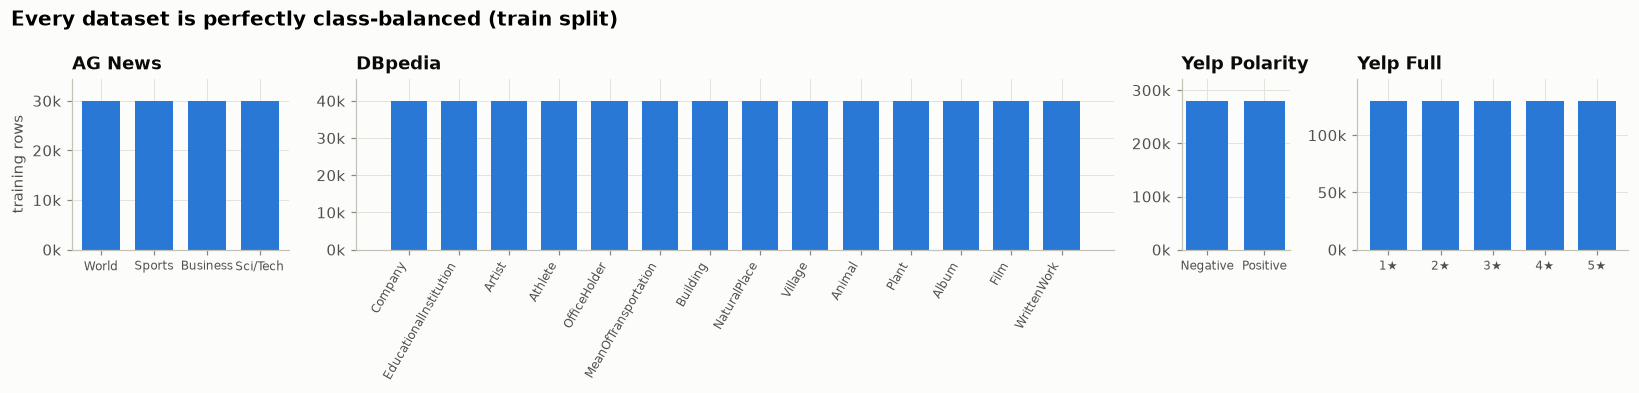

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), gridspec_kw={"width_ratios": [4, 14, 2, 5]})
for ax, name in zip(axes, u.DATASETS):
    counts = frames[name]["train"]["class"].value_counts(sort=False)
    ax.bar(range(len(counts)), counts.values, color=u.SERIES[0], width=0.72)
    ax.set_xticks(
        range(len(counts)),
        counts.index,
        rotation=60 if len(counts) > 5 else 0,
        ha="right" if len(counts) > 5 else "center",
        fontsize=8,
    )
    ax.set_title(name)
    ax.set_ylim(0, counts.max() * 1.15)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:.0f}k"))
axes[0].set_ylabel("training rows")
fig.suptitle(
    "Every dataset is perfectly class-balanced (train split)",
    x=0.01,
    ha="left",
    fontsize=13,
    weight="bold",
)
fig.tight_layout()

In [5]:
balance = {
    name: {
        s: frames[name][s]["label"].value_counts().agg(["min", "max"]).tolist()
        for s in ("train", "test")
    }
    for name in u.DATASETS
}
pd.DataFrame(balance).T.rename(columns=lambda s: f"{s} rows/class [min, max]")

,"train rows/class [min, max]","test rows/class [min, max]"
AG News,"[30000, 30000]","[1900, 1900]"
DBpedia,"[40000, 40000]","[5000, 5000]"
Yelp Polarity,"[280000, 280000]","[19000, 19000]"
Yelp Full,"[130000, 130000]","[10000, 10000]"


Every class has exactly the same count in both splits. So **accuracy and macro-F1 are nearly
interchangeable** on these benchmarks (our reports use macro F1; the paper does not say which F1
averaging it used). Balanced data also means a trivial majority-class baseline scores exactly
1/K: 25% AG News, 7.1% DBpedia, 50% Yelp-P, 20% Yelp-F.

## 3. What the data looks like — examples per class

In [6]:
def show_examples(name, per_class=1, width=230, seed=3):
    frame = frames[name]["train"]
    picks = frame.groupby("class", observed=True).sample(per_class, random_state=seed)
    for _, row in picks.iterrows():
        text = row.text.replace("\\n", " ").replace("\\", "")
        print(f"[{row['class']}] {text[:width]}{'…' if len(text) > width else ''}")
    print()


for name in u.DATASETS:
    print("=" * 20, name, "=" * 20)
    show_examples(name, per_class=2 if name != "DBpedia" else 1)

==================== AG News ====================
[World] Wedding cad comes clean over invite sale (Reuters) Reuters - A wedding guest who sparked a bidding frenzy when he offered for sale a pair of invitations to a wedding he did notwant to attend has admitted that the bride was a forme…
[World] Israeli Forces Attack in Gaza, Killing 7 Arabs Israeli forces continued a major operation in Gaza on Thursday with tanks and armored vehicles to suppress rocket fire into Israel, and in the process killed seven Palestinians.
[Sports] Tennis: Serena Williams Reaches Finals of China Open Top seed Serena Williams of the United States has powered her way into the finals of the China Open tennis tournament in Beijing with a straight sets (6-2, 6-3) victory over fou…
[Sports] Dolphins DT Larry Chester Out for Season (AP) AP - Miami Dolphins defensive tackle Larry Chester will miss the rest of the season because of a torn ligament in his right knee, his agent said Monday.
[Business] Abramovich faces 

Things to notice:

- **AG News** items are a headline plus a one-sentence lede, often with a wire-service tag (`AP -`,
  `Reuters -`, `(SPACE.com)`) that is itself a strong class cue.
- **DBpedia** items are an entity name plus the first sentence of its Wikipedia abstract, which
  almost always *defines* the type ("… is a village in …", "… is an album by …"). That is why every
  model scores about 0.99.
- **Yelp** reviews are long and conversational. In Yelp Full, 2★ vs 3★ vs 4★ depends on subtle
  degree words.

## 4. How long are the inputs, and does the paper's sequence length cut them off?

DHT's compute scales with sequence length (attention is quadratic in it; everything else is linear).
The paper uses **128 tokens** for AG News/DBpedia and **300** for Yelp. We measure length in
*whitespace words* over the full data, and in *BERT WordPiece tokens* (the model's actual unit,
including `[CLS]`/`[SEP]`) using the same pinned `bert-base-uncased` tokenizer as our training.
Tokenizing ~1.4M reviews is unnecessary, so WordPiece lengths use 20,000 random training rows per
dataset. The word-count columns use all rows.

In [7]:
length_rows, wp = [], {}
t0 = time.time()
for name, spec in u.DATASETS.items():
    tr = frames[name]["train"]
    tr["words"] = tr.text.str.count(r"\S+")
    frames[name]["test"]["words"] = frames[name]["test"].text.str.count(r"\S+")
    sample = tr.sample(20_000, random_state=0)
    wp[name] = pd.DataFrame(
        {
            "tokens": u.wordpiece_lengths(sample.text.tolist()),
            "class": sample["class"].values,
            "words": sample.words.values,
        }
    )
    limit = spec["paper_sequence_length"]
    t = wp[name].tokens
    length_rows.append(
        {
            "dataset": name,
            "median words": tr.words.median(),
            "p95 words": tr.words.quantile(0.95),
            "median tokens": t.median(),
            "p95 tokens": t.quantile(0.95),
            "max tokens (sample)": t.max(),
            "tokens / word": (t / tr.loc[sample.index, "words"].clip(lower=1)).median(),
            "paper limit": limit,
            "% truncated at limit": 100 * (t > limit).mean(),
        }
    )
print(f"tokenized 80k texts in {time.time() - t0:.1f}s")
lengths = pd.DataFrame(length_rows).set_index("dataset")
lengths.style.format({c: "{:.1f}" for c in lengths.columns if c not in ("paper limit",)})

tokenized 80k texts in 27.6s


,median words,p95 words,median tokens,p95 tokens,max tokens (sample),tokens / word,paper limit,% truncated at limit
dataset,,,,,,,,
AG News,37.0,53.0,51.0,81.0,357.0,1.3,128,0.8
DBpedia,49.0,83.0,68.0,113.0,1487.0,1.2,128,1.1
Yelp Polarity,97.0,372.0,128.0,502.0,1507.0,1.3,300,16.0
Yelp Full,99.0,370.0,132.0,496.0,1410.0,1.4,300,16.5


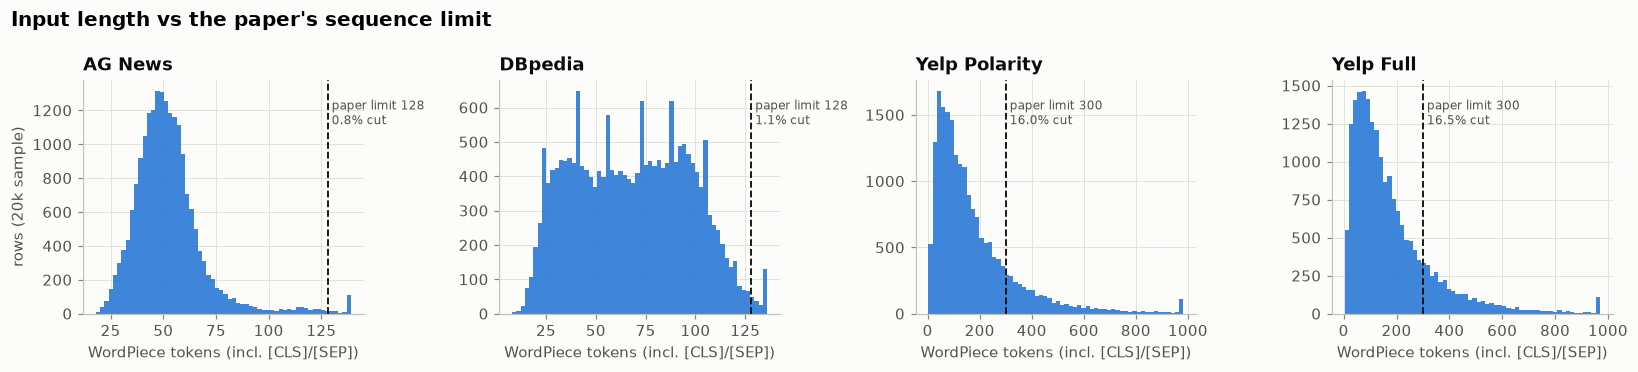

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, (name, spec) in zip(axes, u.DATASETS.items()):
    t = wp[name].tokens
    top = np.percentile(t, 99.5)
    ax.hist(t.clip(upper=top), bins=60, color=u.SERIES[0], alpha=0.9)
    limit = spec["paper_sequence_length"]
    ax.axvline(limit, color=u.INK, lw=1.2, ls="--")
    ax.text(
        limit,
        ax.get_ylim()[1] * 0.92,
        f" paper limit {limit}\n {100 * (t > limit).mean():.1f}% cut",
        color=u.INK2,
        fontsize=8,
        va="top",
    )
    ax.set_title(name)
    ax.set_xlabel("WordPiece tokens (incl. [CLS]/[SEP])")
axes[0].set_ylabel("rows (20k sample)")
fig.suptitle(
    "Input length vs the paper's sequence limit", x=0.01, ha="left", fontsize=13, weight="bold"
)
fig.tight_layout()

**Takeaways on length:**

- AG News and DBpedia are *short*: the median AG News input is about 50 tokens and almost nothing exceeds 128.
  With 128-token padding, **most of every AG News sequence is `[PAD]`**. Our model masks the
  padding, but the dense matmuls (and our FLOP accounting, like the paper's) still run over all 128
  positions.
- The Yelp datasets are long-tailed: a noticeable share of reviews exceed 300 tokens and get
  truncated, so the model never sees their endings, where reviewers often state their verdict.
- Yelp inputs are ~2.5× longer: median ≈130 tokens versus 51 for AG News, and about 16% of reviews
  exceed the 300-token limit. Per-sample compute there is dominated by the longer sequences. The
  paper's biggest savings claims (S-DHT 0.26x on Yelp) are made on these datasets.
- WordPiece produces about 1.2–1.4 tokens per whitespace word on all four corpora.

Does length differ by class? (Violin-style summary using quartiles.)

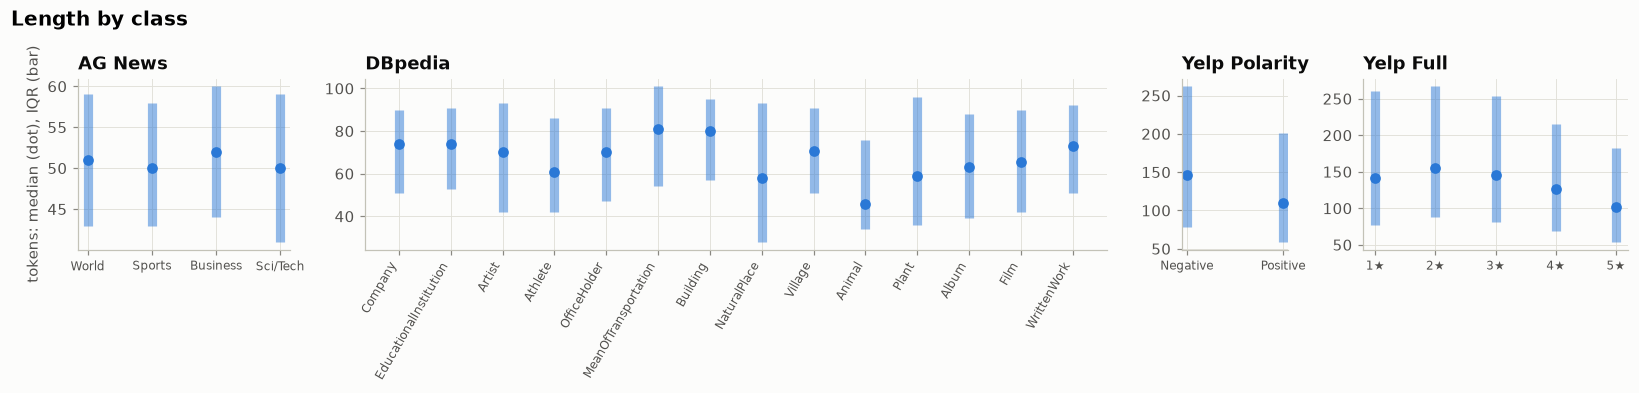

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), gridspec_kw={"width_ratios": [4, 14, 2, 5]})
for ax, name in zip(axes, u.DATASETS):
    g = wp[name].groupby("class", observed=True).tokens
    q = g.quantile([0.25, 0.5, 0.75]).unstack()
    x = np.arange(len(q))
    ax.vlines(x, q[0.25], q[0.75], color=u.SERIES[0], lw=6, alpha=0.5)
    ax.plot(x, q[0.5], "o", color=u.SERIES[0], ms=6)
    ax.set_xticks(
        x,
        q.index,
        rotation=60 if len(q) > 5 else 0,
        ha="right" if len(q) > 5 else "center",
        fontsize=8,
    )
    ax.set_title(name)
axes[0].set_ylabel("tokens: median (dot), IQR (bar)")
fig.suptitle("Length by class", x=0.01, ha="left", fontsize=13, weight="bold")
fig.tight_layout()

Length is only weakly tied to class in the topic datasets. In Yelp, **negative reviews are longer**:
the median is 111 words for negative vs 82 for positive in Yelp Polarity, and length falls steadily
from 2★ (116) to 5★ (77) in Yelp Full. Complaints get detailed. Length alone is therefore a (weak) sentiment signal.
That matters later because a DHT router could learn to key on length-like context features.

## 5. Vocabulary: what words give each class away?

We rank words by a **log-odds ratio with an informative Dirichlet prior** (Monroe et al., 2008):
how much more often a word appears in one class than in the others, shrunk toward zero for rare
words. It is a quick, robust way to see what a classifier *can* latch onto.

In [10]:
WORD = re.compile(r"[a-z][a-z']+")
STOP = set(
    "the a an and or of to in on for with at by from is are was were be been it its this that as i we you he she they my our your their but not no so if".split()
)


def count_by_class(frame, n=40_000):
    sub = frame.sample(min(n, len(frame)), random_state=1)
    counts = {c: Counter() for c in frame["class"].cat.categories}
    for text, c in zip(sub.text.str.lower(), sub["class"]):
        counts[c].update(w for w in WORD.findall(text.replace("\\n", " ")) if w not in STOP)
    return counts


def log_odds(counts, top=8, alpha0=500.0):
    total = Counter()
    for c in counts.values():
        total.update(c)
    vocab = [w for w, n in total.items() if n >= 20]
    tot_n = sum(total[w] for w in vocab)
    prior = {w: alpha0 * total[w] / tot_n for w in vocab}
    out = {}
    for cls, cnt in counts.items():
        n_i = sum(cnt[w] for w in vocab)
        n_j = tot_n - n_i
        scores = []
        for w in vocab:
            a, yi, yj = prior[w], cnt[w], total[w] - cnt[w]
            d = np.log((yi + a) / (n_i + alpha0 - yi - a)) - np.log(
                (yj + a) / (n_j + alpha0 - yj - a)
            )
            scores.append((d / np.sqrt(1 / (yi + a) + 1 / (yj + a)), w))
        out[cls] = [w for _, w in sorted(scores, reverse=True)[:top]]
    return out


for name in u.DATASETS:
    words = log_odds(count_by_class(frames[name]["train"]))
    print(f"— {name}")
    for cls, ws in words.items():
        print(f"   {cls:>22}: {', '.join(ws)}")

— AG News
                    World: iraq, president, afp, minister, people, police, bush, leader
                   Sports: his, game, season, team, win, night, victory, lead
                 Business: oil, prices, inc, stocks, percent, reuters, sales, company
                 Sci/Tech: microsoft, software, internet, search, computer, web, music, online


— DBpedia
                  Company: company, based, founded, services, group, inc, owned, corporation
   EducationalInstitution: school, high, university, college, located, public, education, students
                   Artist: born, his, singer, artist, writer, songwriter, music, musician
                  Athlete: born, who, played, professional, player, plays, football, team
             OfficeHolder: member, served, born, party, politician, president, state, democratic
     MeanOfTransportation: class, built, war, navy, aircraft, royal, ship, launched
                 Building: house, church, built, building, located, historic, national, street
             NaturalPlace: river, lake, mountain, km, range, romania, mount, mountains
                  Village: district, county, village, mi, km, province, central, east
                   Animal: family, species, found, genus, sea, described, marine, mm
                    Plant: species, family, genus, plant, native, endemic, common, h

— Yelp Polarity
                 Negative: told, said, asked, minutes, manager, then, her, bad
                 Positive: great, love, delicious, amazing, always, best, friendly, good


— Yelp Full
                       1★: told, never, worst, said, manager, me, called, her
                       2★: bland, better, mediocre, ok, disappointing, meh, nothing, ordered
                       3★: good, pretty, decent, bit, ok, little, overall, though
                       4★: great, good, delicious, nice, tasty, definitely, friendly, enjoyed
                       5★: great, amazing, love, best, awesome, delicious, always, highly


- **AG News**: the distinctive words are the topic itself (sports teams/leagues, companies/markets,
  software/space) plus source tags. A bag of words is already very strong.
- **DBpedia**: the definitional nouns (*village, album, species, footballer, school*) almost name
  the class.
- **Yelp Polarity**: positive reviews use evaluative words (*great, love, delicious, amazing*).
  Negative reviews read as *stories of a bad service incident* (*told, said, asked, minutes,
  manager*), which is a narrative cue rather than a sentiment word.
- **Yelp Full**: the extreme classes look like polarity, but **the middle classes use hedged words**
  (2★ *bland, mediocre, ok, meh*; 3★ *pretty, decent, bit, ok, though*). That is exactly where
  classifiers fail.

## 6. Data-quality quirks

These are raw research corpora with known artifacts. We count them because our pipeline
deliberately *does not clean* them (`ag_news.read_csv` keeps the text verbatim, matching the common
benchmark setup).

In [11]:
q = []
for name in u.DATASETS:
    tr, te = frames[name]["train"], frames[name]["test"]
    train_set = set(tr.text)
    q.append(
        {
            "dataset": name,
            "dup texts in train": int(tr.text.duplicated().sum()),
            "dup texts w/ conflicting labels": int(tr.groupby("text").label.nunique().gt(1).sum()),
            "test texts also in train": int(te.text.isin(train_set).sum()),
            '% w/ literal \\n or \\" escapes': 100
            * tr.text.str.contains(r'\\[n"]', regex=True).mean(),
            "% w/ HTML entity (#36; &lt; …)": 100
            * tr.text.str.contains(r"#\d+;|&[a-z]+;", regex=True).mean(),
            "empty texts": int((tr.text.str.strip() == "").sum()),
        }
    )
pd.DataFrame(q).set_index("dataset").style.format(precision=2)

,dup texts in train,dup texts w/ conflicting labels,test texts also in train,"% w/ literal \n or \"" escapes",% w/ HTML entity (#36; < …),empty texts
dataset,,,,,,
AG News,0,0,0,0.23,29.56,0
DBpedia,0,0,0,0.00,0.00,0
Yelp Polarity,0,0,0,53.44,0.00,0
Yelp Full,0,0,0,54.96,0.01,0


- **No exact duplicate texts, no conflicting labels and no exact train/test overlap** in any of the
  four corpora. The releases were deduplicated, so test scores are not inflated by leakage. (Near-
  duplicates such as the same wire story with a different lede are not checked here.)
- **Escaped text is very common**: ~30% of AG News rows contain mangled HTML entities (`#39;` = `'`,
  `#36;` = `$`, `&lt;b&gt;`), and ~55% of Yelp reviews contain literal `\n` / `\"` sequences.
  BERT's WordPiece splits these into junk sub-tokens (`#`, `39`, `;`), which waste positions within
  the 128/300 budget and add noise. They are kept verbatim here, as in the common benchmark setup.

## 7. How hard is each task? A bag-of-words baseline

To see how much each dataset needs a deep contextual model (and so how much room a
*depth-skipping* method like DHT has), we train a **multinomial Naive Bayes** on unigrams. It is a
pure word-counting model with no context and no order. It uses 100k training rows per dataset and is
scored on the full public test set.

In [12]:
def nb_baseline(name, n_train=100_000):
    tr = frames[name]["train"].sample(n_train, random_state=2)
    te = frames[name]["test"]
    K = tr.label.nunique()
    vocab = {}

    def encode(texts, grow):
        doc, tok = [], []
        for i, t in enumerate(texts):
            for w in WORD.findall(t.lower()):
                j = vocab.get(w)
                if j is None and grow:
                    j = vocab[w] = len(vocab)
                if j is not None:
                    doc.append(i)
                    tok.append(j)
        return np.asarray(doc), np.asarray(tok)

    d, t = encode(tr.text.tolist(), True)
    V = len(vocab)
    counts = np.zeros((K, V))
    np.add.at(counts, (tr.label.values[d], t), 1)
    logp = np.log(counts + 1) - np.log(counts.sum(1, keepdims=True) + V)  # Laplace smoothing
    d2, t2 = encode(te.text.tolist(), False)
    scores = np.zeros((len(te), K))
    np.add.at(scores, d2, logp[:, t2].T)
    pred = scores.argmax(1)
    y = te.label.values
    f1s = []
    for k in range(K):
        tp = ((pred == k) & (y == k)).sum()
        fp = ((pred == k) & (y != k)).sum()
        fn = ((pred != k) & (y == k)).sum()
        f1s.append(2 * tp / max(2 * tp + fp + fn, 1))
    return pred, {"accuracy": (pred == y).mean(), "macro F1": np.mean(f1s), "vocab": V}


nb, nb_rows = {}, []
for name in u.DATASETS:
    pred, m = nb_baseline(name)
    nb[name] = pred
    nb_rows.append(
        {
            "dataset": name,
            "NB accuracy": m["accuracy"],
            "NB macro F1": m["macro F1"],
            "paper 12-layer BERT F1": f1.loc["12-VaBERT", name],
            "paper T-DHT F1": f1.loc["T-DHT", name],
            "chance": 1 / frames[name]["train"].label.nunique(),
        }
    )
difficulty = pd.DataFrame(nb_rows).set_index("dataset")
difficulty["BERT gain over NB"] = difficulty["paper 12-layer BERT F1"] - difficulty["NB macro F1"]
difficulty.style.format("{:.3f}")

,NB accuracy,NB macro F1,paper 12-layer BERT F1,paper T-DHT F1,chance,BERT gain over NB
dataset,,,,,,
AG News,0.899,0.898,0.944,0.945,0.250,0.046
DBpedia,0.957,0.957,0.993,0.992,0.071,0.036
Yelp Polarity,0.867,0.866,0.960,0.958,0.500,0.094
Yelp Full,0.521,0.522,0.659,0.635,0.200,0.137


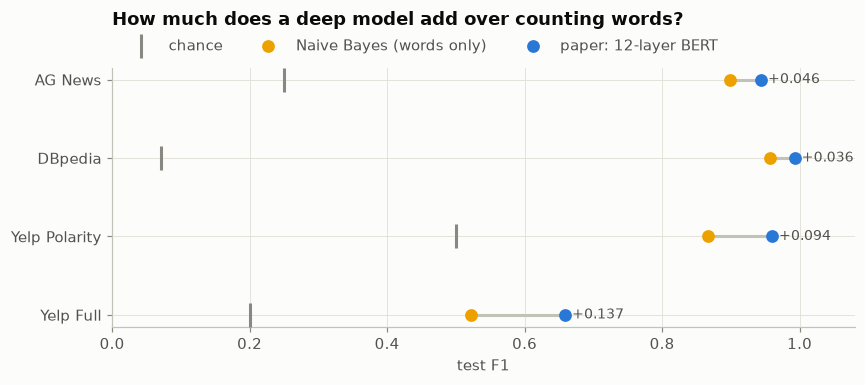

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.6))
names = list(u.DATASETS)
y = np.arange(len(names))
for label, col, color, marker in [
    ("chance", "chance", u.MUTED, "|"),
    ("Naive Bayes (words only)", "NB macro F1", u.SERIES[3], "o"),
    ("paper: 12-layer BERT", "paper 12-layer BERT F1", u.SERIES[0], "o"),
]:
    ax.scatter(
        difficulty[col],
        y,
        color=color,
        s=70 if marker == "o" else 250,
        marker=marker,
        label=label,
        zorder=3,
    )
for i, n in enumerate(names):
    ax.plot(
        [difficulty.loc[n, "NB macro F1"], difficulty.loc[n, "paper 12-layer BERT F1"]],
        [i, i],
        color=u.AXIS,
        lw=2,
        zorder=2,
    )
    ax.text(
        difficulty.loc[n, "paper 12-layer BERT F1"] + 0.01,
        i,
        f"+{difficulty.loc[n, 'BERT gain over NB']:.3f}",
        va="center",
        color=u.INK2,
        fontsize=9,
    )
ax.set_yticks(y, names)
ax.invert_yaxis()
ax.set_xlim(0, 1.08)
ax.set_xlabel("test F1")
ax.legend(loc="lower left", ncol=3, bbox_to_anchor=(0, 1.0))
ax.set_title("How much does a deep model add over counting words?", pad=28)
fig.tight_layout()

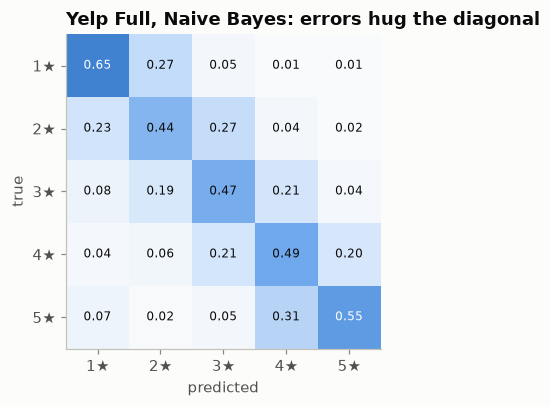

In [14]:
from matplotlib.colors import LinearSegmentedColormap

BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#fcfcfb", "#cde2fb", "#6da7ec", "#256abf", "#0d366b"]
)


def confusion(y, p, K):
    m = np.zeros((K, K))
    np.add.at(m, (y, p), 1)
    return m / m.sum(1, keepdims=True)


y = frames["Yelp Full"]["test"].label.values
m = confusion(y, nb["Yelp Full"], 5)
fig, ax = plt.subplots(figsize=(4.4, 3.8))
ax.imshow(m, cmap=BLUES, vmin=0, vmax=1)
ax.grid(False)
for i in range(5):
    for j in range(5):
        ax.text(
            j,
            i,
            f"{m[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if m[i, j] > 0.5 else u.INK,
        )
ax.set_xticks(range(5), u.class_names("Yelp Full"))
ax.set_yticks(range(5), u.class_names("Yelp Full"))
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title("Yelp Full, Naive Bayes: errors hug the diagonal")
fig.tight_layout()

**Difficulty ranking:** DBpedia < AG News < Yelp Polarity ≪ Yelp Full.

- On **DBpedia and AG News**, word counting alone gets most of the way. A 12-layer BERT adds only a
  few points. For these datasets **most samples don't need a deep contextual model**, which is the
  premise that makes sample-based depth skipping (DHT) attractive.
- On **Yelp Polarity**, BERT's gain is larger (negation and contrast matter).
- **Yelp Full** is hard for everyone: errors are almost all *adjacent-star* confusions (the matrix
  mass is next to the diagonal). The labels are ordinal and noisy, which is why the paper's best F1
  is 0.66. It is also where DHT *loses the most* in the paper (T-DHT 0.635 vs BERT 0.659): the
  cheaper paths can't resolve the subtle middle classes.

---

# Part 2 — DHT vs no DHT on AG News (our runs)

Only AG News was trained end-to-end in this repo (the paper's other datasets are 5–5.4× larger;
each full run would take roughly 15+ hours on this machine). Setup (matched, seed 7): pinned BERT-base
weights, 114k train / 6k validation (held out from train) / 7.6k public test, 3 epochs, batch 8,
AdamW 2e-5, sequence length 128.

| | what runs per sample |
|---|---|
| **Fixed BERT (no DHT)** | all 12 layers × 12 heads, always |
| **T-DHT** | 3 full-head prefix layers → a UCB bandit picks total depth ∈ {3,6,9,12} → for each 3-layer group, a second UCB picks a head count ∈ {8,10,12} and Thompson sampling picks *which* heads |

### 8. Headline numbers

In [15]:
models = [m for m in ["Fixed BERT", "T-DHT"] if m in u.available_models()]
preds = {m: u.load_predictions(m) for m in models}
raw_test = frames["AG News"]["test"]
for m, frame in preds.items():
    frame["text"] = raw_test.text.values[frame.source_index]
    frame["class"] = pd.Categorical.from_codes(frame.label, u.AG_NEWS_CLASSES)
    frame["flop_ratio"] = [
        u.relative_matmul_flops(d, c) for d, c in zip(frame.total_depth, frame.group_counts)
    ]

rows = []
for m in models:
    s = json.loads((u.ANALYSIS / f"{u.EXPORTS[m]}.test.summary.json").read_text())
    summ = u.run_summary(m)
    bench = u.run_json(m, "benchmark.json")
    rows.append(
        {
            "model": m,
            "export reproduces recorded F1": s["matches_recorded"],
            "validation macro F1": summ["best_validation_score"],
            "test macro F1": s["metrics"]["macro_f1"],
            "test accuracy": s["metrics"]["accuracy"],
            "paper F1": f1.loc["12-VaBERT" if m == "Fixed BERT" else m, "AG News"],
            "task matmul FLOPs (test)": preds[m].flop_ratio.mean(),
            "paper inference FLOPs": paper.query("cost_phase=='inference' and dataset=='AG News'")
            .set_index("model")
            .flop_ratio["12-VaBERT" if m == "Fixed BERT" else m],
            "mean depth": preds[m].total_depth.mean(),
            "throughput (samples/s, MPS b=8)": bench["samples_per_second"],
            "training step time (h)": summ.get(
                "cumulative_training_step_seconds", summ.get("segment_training_seconds", np.nan)
            )
            / 3600,
        }
    )
headline = pd.DataFrame(rows).set_index("model")
headline.style.format(
    {c: "{:.4f}" for c in ["validation macro F1", "test macro F1", "test accuracy"]}
    | {
        "paper F1": "{:.3f}",
        "task matmul FLOPs (test)": "{:.3f}x",
        "paper inference FLOPs": "{:.2f}x",
        "mean depth": "{:.2f}",
        "throughput (samples/s, MPS b=8)": "{:.1f}",
        "training step time (h)": "{:.2f}",
    }
)

,export reproduces recorded F1,validation macro F1,test macro F1,test accuracy,paper F1,task matmul FLOPs (test),paper inference FLOPs,mean depth,"throughput (samples/s, MPS b=8)",training step time (h)
model,,,,,,,,,,
Fixed BERT,True,0.9480,0.9490,0.9491,0.944,1.000x,1.00x,12.00,174.1,1.88
T-DHT,True,0.9438,0.9400,0.9400,0.945,0.386x,0.81x,4.75,68.1,2.96


How to read this:

- **Accuracy:** T-DHT gives up about 0.9 points of macro F1 relative to the fixed model on the same
  data, while its *task path* uses about 39% of the fixed model's attention+FFN matmul FLOPs.
- **Paper vs us:** the paper reports T-DHT *slightly above* BERT (0.945 vs 0.944). We see a small
  drop. Our fixed baseline (0.949) is also stronger than the paper's (0.944).
- **FLOPs ≠ speed.** The FLOP ratio counts only the selected task path. Adding the routing prefix
  pass brings it to about 0.64x. In wall-clock terms the per-sample DHT implementation is **~2.5× slower**,
  because each sample runs its own architecture, the prefix runs twice, and bandit math runs on the CPU.
  The paper also reports FLOP estimates, not wall-clock time.

### 9. Where does DHT lose accuracy?

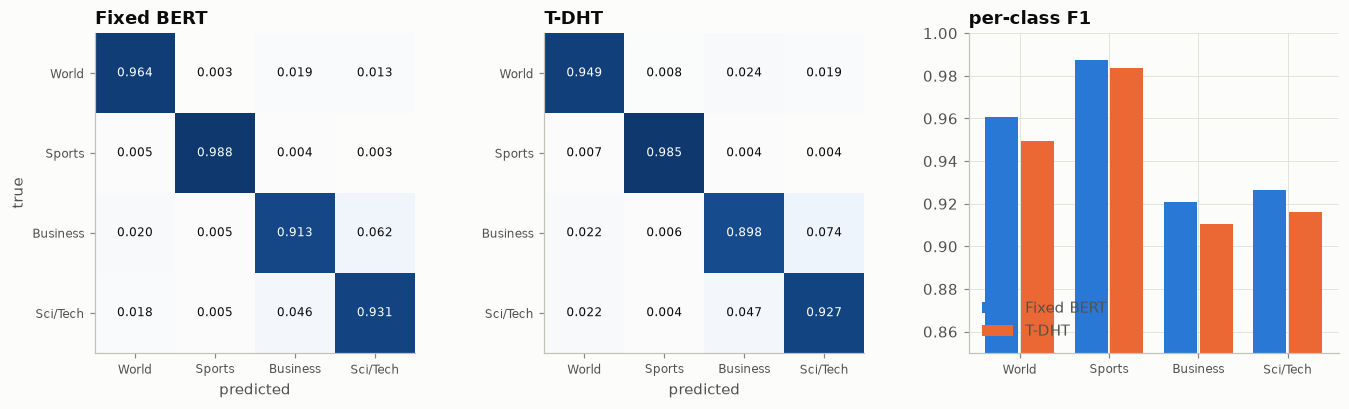

In [16]:
fig, axes = plt.subplots(1, len(models) + 1, figsize=(4.2 * (len(models) + 1), 3.8))
for ax, m in zip(axes, models):
    cm = confusion(preds[m].label.values, preds[m].prediction.values, 4)
    ax.imshow(cm, cmap=BLUES, vmin=0, vmax=1)
    ax.grid(False)
    for i in range(4):
        for j in range(4):
            ax.text(
                j,
                i,
                f"{cm[i, j]:.3f}",
                ha="center",
                va="center",
                fontsize=8,
                color="white" if cm[i, j] > 0.5 else u.INK,
            )
    ax.set_xticks(range(4), u.AG_NEWS_CLASSES, fontsize=8)
    ax.set_yticks(range(4), u.AG_NEWS_CLASSES, fontsize=8)
    ax.set_title(m)
    ax.set_xlabel("predicted")
axes[0].set_ylabel("true")


def per_class_f1(frame):
    out = []
    for k in range(4):
        tp = ((frame.prediction == k) & (frame.label == k)).sum()
        fp = ((frame.prediction == k) & (frame.label != k)).sum()
        fn = ((frame.prediction != k) & (frame.label == k)).sum()
        out.append(2 * tp / (2 * tp + fp + fn))
    return out


ax = axes[-1]
w = 0.8 / len(models)
for i, m in enumerate(models):
    ax.bar(
        np.arange(4) + (i - (len(models) - 1) / 2) * w,
        per_class_f1(preds[m]),
        width=w * 0.92,
        color=u.MODEL_COLORS[m],
        label=m,
    )
ax.set_xticks(range(4), u.AG_NEWS_CLASSES, fontsize=8)
ax.set_ylim(0.85, 1.0)
ax.set_title("per-class F1")
ax.legend(loc="lower left")
fig.tight_layout()

Both models have the same weak spot: **Business ↔ Sci/Tech** (tech-company earnings, telecom
deals, and so on). T-DHT loses about one point of F1 on each of World, Business and Sci/Tech, and only
0.4 on Sports, which both models nearly solve (F1 ≈ 0.98–0.99).

### 10. What architecture does DHT pick, and for which samples?

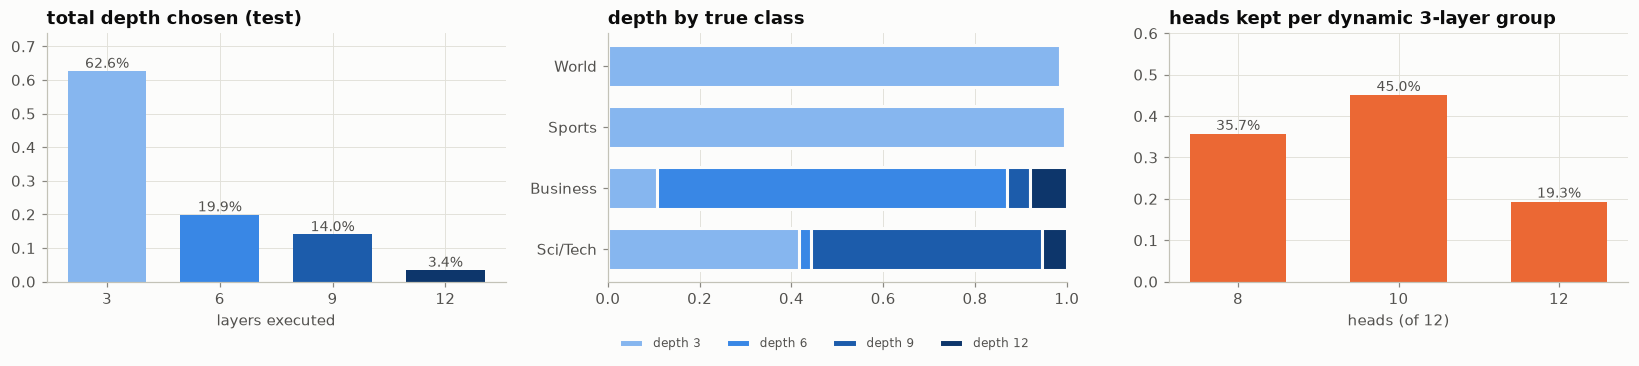

In [17]:
t = preds["T-DHT"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
ax = axes[0]
share = t.total_depth.value_counts(normalize=True).sort_index()
ax.bar(
    [str(d) for d in share.index],
    share.values,
    color=[u.DEPTH_COLORS[d] for d in share.index],
    width=0.7,
)
for x, v in enumerate(share.values):
    ax.text(x, v + 0.01, f"{v:.1%}", ha="center", color=u.INK2, fontsize=9)
ax.set_title("total depth chosen (test)")
ax.set_xlabel("layers executed")
ax.set_ylim(0, share.max() * 1.18)

ax = axes[1]
ct = pd.crosstab(t["class"], t.total_depth, normalize="index")
left = np.zeros(4)
for d in ct.columns:
    ax.barh(
        range(4),
        ct[d],
        left=left,
        color=u.DEPTH_COLORS[d],
        label=f"depth {d}",
        height=0.7,
        edgecolor=u.SURFACE,
        linewidth=2,
    )
    left += ct[d].values
ax.set_yticks(range(4), ct.index)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_title("depth by true class")
ax.legend(ncol=4, loc="lower left", bbox_to_anchor=(0, -0.32), fontsize=8)

ax = axes[2]
counts = Counter(c for cs in t.group_counts for c in cs)
tot = sum(counts.values())
ks = sorted(counts)
ax.bar([str(k) for k in ks], [counts[k] / tot for k in ks], color=u.SERIES[1], width=0.6)
for x, k in enumerate(ks):
    ax.text(
        x, counts[k] / tot + 0.01, f"{counts[k] / tot:.1%}", ha="center", color=u.INK2, fontsize=9
    )
ax.set_title("heads kept per dynamic 3-layer group")
ax.set_xlabel("heads (of 12)")
ax.set_ylim(0, 0.6)
fig.tight_layout()

The router is **aggressive**: 62.6% of test samples stop after the 3 always-on prefix layers, and
only 3.4% go to all 12. It clearly routes by class. **World and Sports mostly exit early** (mean
compute ≈0.25x, i.e. nearly always depth 3), while **Business and Sci/Tech go deeper** (≈0.50–0.53x),
matching the class pair both models find hardest. The two hard classes are routed differently:
**Business mostly goes to depth 6**, while **Sci/Tech splits between depth 3 and depth 9**. Remember that the router
never sees labels. It learned this from the 3-layer context features plus the loss×depth reward.

Is depth tied to *how hard the sample is*? We use the **fixed model's loss on the same sample** as an
independent difficulty measure, together with input length.

In [18]:
f = preds["Fixed BERT"]
joint = pd.DataFrame(
    {
        "depth": t.total_depth,
        "tokens": t.token_length,
        "fixed_loss": f.loss,
        "fixed_conf": f.confidence,
        "fixed_ok": f.correct,
        "dht_ok": t.correct,
        "class": t["class"],
        "text": t.text,
        "dht_pred": t.prediction,
        "fixed_pred": f.prediction,
        "label": t.label,
        "counts": t.group_counts,
        "flops": t.flop_ratio,
        "dht_conf": t.confidence,
    }
)
by_depth = joint.groupby("depth").agg(
    samples=("depth", "size"),
    median_tokens=("tokens", "median"),
    fixed_mean_loss=("fixed_loss", "mean"),
    fixed_conf=("fixed_conf", "mean"),
    fixed_acc=("fixed_ok", "mean"),
    dht_acc=("dht_ok", "mean"),
)
by_depth["DHT − fixed (acc)"] = by_depth.dht_acc - by_depth.fixed_acc
by_depth.style.format(
    {
        "fixed_mean_loss": "{:.3f}",
        "fixed_conf": "{:.3f}",
        "fixed_acc": "{:.3f}",
        "dht_acc": "{:.3f}",
        "DHT − fixed (acc)": "{:+.3f}",
    }
)

,samples,median_tokens,fixed_mean_loss,fixed_conf,fixed_acc,dht_acc,DHT − fixed (acc)
depth,,,,,,,
3,4759,50.000000,0.151,0.982,0.961,0.949,-0.012
6,1514,53.000000,0.155,0.982,0.961,0.960,-0.001
9,1066,50.000000,0.250,0.954,0.921,0.914,-0.008
12,261,43.000000,0.612,0.882,0.778,0.762,-0.015


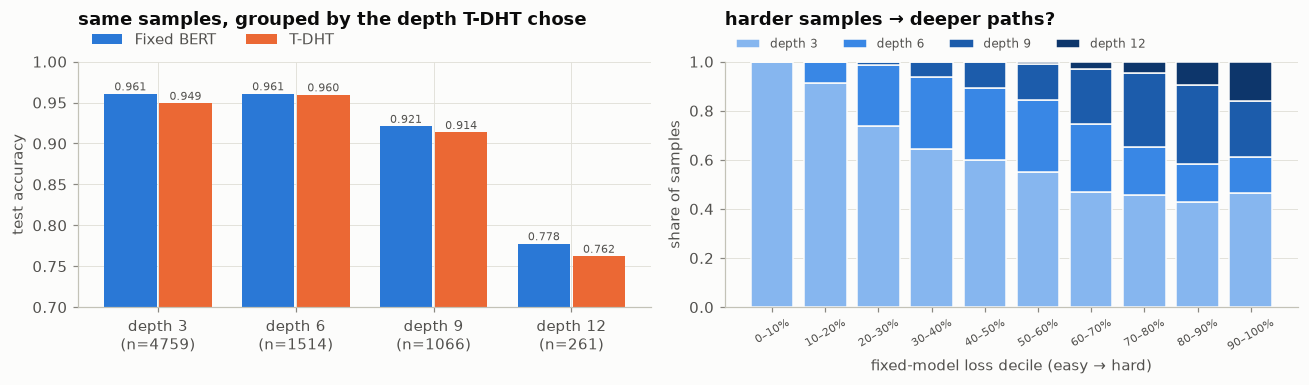

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
ax = axes[0]
x = np.arange(len(by_depth))
ax.bar(x - 0.2, by_depth.fixed_acc, 0.38, color=u.MODEL_COLORS["Fixed BERT"], label="Fixed BERT")
ax.bar(x + 0.2, by_depth.dht_acc, 0.38, color=u.MODEL_COLORS["T-DHT"], label="T-DHT")
ax.set_xticks(x, [f"depth {d}\n(n={n})" for d, n in zip(by_depth.index, by_depth.samples)])
ax.set_ylim(0.7, 1.0)
ax.set_ylabel("test accuracy")
ax.legend(loc="lower left", ncol=2, bbox_to_anchor=(0, 1.0))
for xi, (fa, da) in enumerate(zip(by_depth.fixed_acc, by_depth.dht_acc)):
    ax.text(xi - 0.2, fa + 0.004, f"{fa:.3f}", ha="center", fontsize=7, color=u.INK2)
    ax.text(xi + 0.2, da + 0.004, f"{da:.3f}", ha="center", fontsize=7, color=u.INK2)
ax.set_title("same samples, grouped by the depth T-DHT chose", pad=24)
ax = axes[1]
bins = pd.qcut(joint.fixed_loss.rank(method="first"), 10, labels=False)
share = pd.crosstab(bins, joint.depth, normalize="index")
left = np.zeros(len(share))
for d in share.columns:
    ax.bar(
        share.index,
        share[d],
        bottom=left,
        color=u.DEPTH_COLORS[d],
        label=f"depth {d}",
        width=0.8,
        edgecolor=u.SURFACE,
        linewidth=1,
    )
    left += share[d].values
ax.set_xticks(range(10), [f"{i * 10}–{i * 10 + 10}%" for i in range(10)], fontsize=7, rotation=30)
ax.set_xlabel("fixed-model loss decile (easy → hard)")
ax.set_ylabel("share of samples")
ax.set_ylim(0, 1)
ax.legend(ncol=4, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=8)
ax.set_title("harder samples → deeper paths?", pad=24)
fig.tight_layout()

Reading these two charts together:

- Samples the router sends **deep are genuinely harder**. The fixed model's own accuracy on them
  falls from 0.961 (depth 3/6) to 0.921 (depth 9) to 0.778 (depth 12). In the easiest fixed-loss
  decile 100% of samples exit at depth 3; in the hardest deciles depth 9/12 take ~40–45%. So the
  3-layer context carries a real "this one is hard" signal.
- The signal is imperfect: **even in the hardest decile ~46% of samples still exit at depth 3**.
  Most of DHT's absolute accuracy loss (≈57 of the net 69 samples) sits in that depth-3 bucket.
  Early exits are usually right, but 3 layers can't fix hard samples the router mistakes for easy
  ones. This is the core tradeoff of sample-based depth.

### 11. Agreement: when does skipping computation change the answer?

In [20]:
agree = pd.crosstab(
    joint.fixed_ok.map({True: "fixed ✓", False: "fixed ✗"}),
    joint.dht_ok.map({True: "T-DHT ✓", False: "T-DHT ✗"}),
    margins=True,
)
display(agree)
print(f"Prediction agreement: {(joint.dht_pred == joint.fixed_pred).mean():.3%} of test samples")

dht_ok,T-DHT ✓,T-DHT ✗,All
fixed_ok,,,
fixed ✓,7052,161,7213
fixed ✗,92,295,387
All,7144,456,7600


Prediction agreement: 96.342% of test samples


In [21]:
def show(frame, title, n=4, seed=0):
    print(f"\n▶ {title}  ({len(frame)} samples)")
    for _, r in frame.sample(min(n, len(frame)), random_state=seed).iterrows():
        text = r.text.replace("\\", " ")
        heads = "/".join(map(str, r.counts)) if r.counts else "—"
        print(
            f"  true={u.AG_NEWS_CLASSES[r.label]:<8} fixed→{u.AG_NEWS_CLASSES[r.fixed_pred]:<8} DHT→{u.AG_NEWS_CLASSES[r.dht_pred]:<8}"
            f" depth={r.depth:>2} heads/group={heads:<8} compute={r.flops:.2f}x"
        )
        print(f"     “{text[:170]}{'…' if len(text) > 170 else ''}”")


show(
    joint[joint.fixed_ok & joint.dht_ok & (joint.depth == 3)],
    "Both right, DHT used only 3 layers (the common, cheap case)",
)
show(
    joint[joint.fixed_ok & joint.dht_ok & (joint.depth == 12)], "Both right, DHT used all 12 layers"
)
show(joint[joint.fixed_ok & ~joint.dht_ok], "Fixed right, DHT wrong (skipping hurt)")
show(joint[~joint.fixed_ok & joint.dht_ok], "DHT right, fixed wrong")
show(joint[~joint.fixed_ok & ~joint.dht_ok], "Both wrong (often label noise / genuinely ambiguous)")


▶ Both right, DHT used only 3 layers (the common, cheap case)  (4478 samples)
  true=Sports   fixed→Sports   DHT→Sports   depth= 3 heads/group=—        compute=0.25x
     “Jerkens makes right call with Society Selection Trainer Allen Jerkens hemmed and hawed this past week over running Society Selection in Saturday #39;s Grade 1 Alabama at …”
  true=World    fixed→World    DHT→World    depth= 3 heads/group=—        compute=0.25x
     “EU Move on Cyprus Eases Way for Turkey Deal  BRUSSELS (Reuters) - The European Union and Turkey inched  toward a historic agreement on starting membership talks on  Frida…”
  true=World    fixed→World    DHT→World    depth= 3 heads/group=—        compute=0.25x
     “Iran Denies Any Nuclear Activity At Suspect Site Parchin VIENNA (AFP) - Iran denied that it had carried out any nuclear-related activity at the Parchin military site whic…”
  true=World    fixed→World    DHT→World    depth= 3 heads/group=—        compute=0.25x
     “Staying or Going? Some Pos

Patterns in these examples:

- **Cheap and correct:** headlines whose topic is explicit (team names, "shares rose", a product
  launch).
- **Skipping hurt (161 samples):** 59% of them were routed to depth 3. About half (75) are
  Business↔Sci/Tech boundary cases (a tech company in a financial story), and about a quarter are
  World stories pulled toward Business/Sci-Tech by a surface keyword. A shallow path over-trusts
  such cues.
- **DHT sometimes wins (92 samples).** It helps on some samples and hurts on others, and the net
  result is −69 samples (−0.9 points).
- **Both wrong:** many are debatable labels in the dataset itself (a business story about a tech
  firm, a world story about sports politics). No amount of depth fixes those.

### 12. Compute actually spent per sample

class
World       0.256x
Sports      0.252x
Business    0.501x
Sci/Tech    0.534x


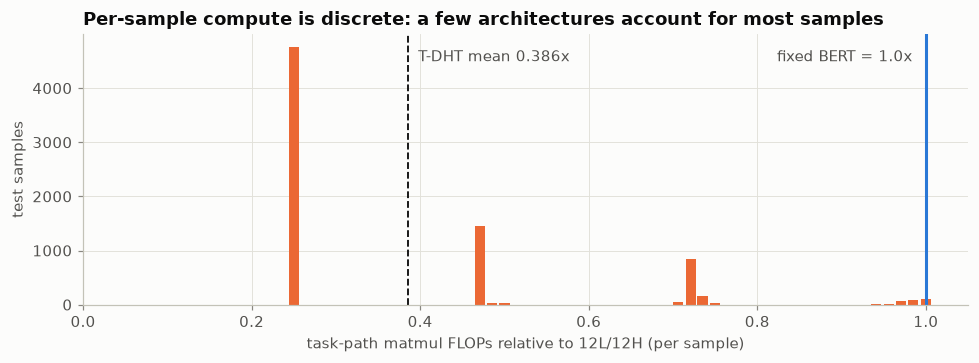

In [22]:
fig, ax = plt.subplots(figsize=(9, 3.4))
vals = t.flop_ratio.round(3).value_counts().sort_index()
ax.bar(vals.index, vals.values, width=0.012, color=u.SERIES[1])
ax.axvline(1.0, color=u.MODEL_COLORS["Fixed BERT"], lw=2)
ax.text(0.99, ax.get_ylim()[1] * 0.9, "fixed BERT = 1.0x ", ha="right", color=u.INK2)
ax.axvline(t.flop_ratio.mean(), color=u.INK, ls="--", lw=1.2)
ax.text(
    t.flop_ratio.mean(),
    ax.get_ylim()[1] * 0.9,
    f"  T-DHT mean {t.flop_ratio.mean():.3f}x",
    color=u.INK2,
)
ax.set_xlabel("task-path matmul FLOPs relative to 12L/12H (per sample)")
ax.set_ylabel("test samples")
ax.set_xlim(0, 1.05)
ax.set_title("Per-sample compute is discrete: a few architectures account for most samples")
fig.tight_layout()
print(
    joint.groupby("class", observed=True)
    .flops.mean()
    .rename("mean compute by class")
    .map("{:.3f}x".format)
    .to_string()
)

### 13. How the routing policy evolved during training (paper Fig. 2 analogue)

The paper's Fig. 2 shows the 3-layer option becoming dominant as training proceeds. Every
training step in our run logs each sample's architecture, so we can draw the same plot. Shares
are computed over bins of 4,000 consecutive trained samples.

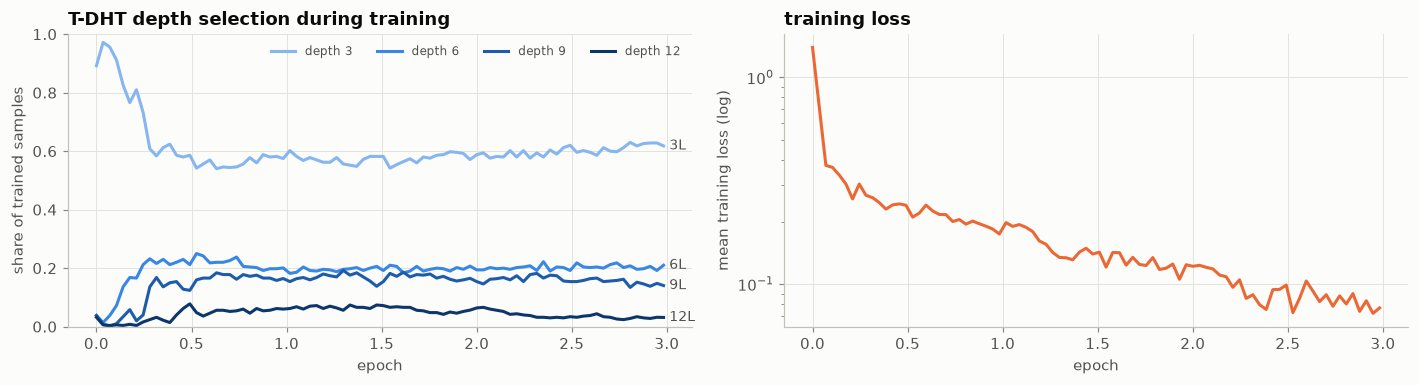

In [23]:
sel = u.training_selections("T-DHT", every=4000)
depth_share = pd.crosstab(sel.bin, sel.depth, normalize="index")
loss = sel.groupby("bin").loss.mean()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
ax = axes[0]
xs = depth_share.index * 4000 / 114000
for d in depth_share.columns:
    ax.plot(xs, depth_share[d], color=u.DEPTH_COLORS[d], label=f"depth {d}")
    ax.text(xs[-1] + 0.03, depth_share[d].iloc[-1], f"{d}L", color=u.INK2, va="center", fontsize=9)
ax.set_xlabel("epoch")
ax.set_ylabel("share of trained samples")
ax.set_ylim(0, 1)
ax.legend(ncol=4, loc="upper right", fontsize=8)
ax.set_title("T-DHT depth selection during training")
ax = axes[1]
ax.plot(xs, loss, color=u.MODEL_COLORS["T-DHT"])
ax.set_yscale("log")
ax.set_xlabel("epoch")
ax.set_ylabel("mean training loss (log)")
ax.set_title("training loss")
fig.tight_layout()

**This is the opposite of the paper's Fig. 2**, which reports the 3-layer option chosen *less* at
first and *more* after ~5 episodes. In our run the 3-layer path takes **89–97% of samples in the
first ~12k samples**, then *declines* to a stable ~55–60% by mid-epoch 1 as depths 6/9 gain share.
It stays there for the remaining two epochs, and the training loss falls smoothly throughout (the
paper's stability claim does hold).

A plausible (not proven) mechanism is the reward: r = mean_prev(loss·L) / (loss·L). Early on, the
loss is ≈1.4 for every sample regardless of depth, so the depth factor L alone decides the reward and
depth 3 wins. Once the model has learned, loss differences between easy and hard samples dominate
L, and deeper paths start earning rewards on hard samples. The paper does not give enough detail
(initialization, reward scale, exploration constant) to tell which setup produced its opposite trend.

# Part 3 — One sample at a time: what full BERT and DHT actually do

The charts above are averages. This part follows **individual sentences** through both models so
you can see:

- exactly what goes in
- what each model computes
- what each model predicts
- *why*

### First, what is (and isn't) "masked"?

"Mask" means three different things around BERT. Only one of them involves words:

| "Mask" | Where it happens | In our AG News models? |
|---|---|---|
| **`[MASK]` word masking** | BERT's *pre*-training: hide ~15% of words, predict them | **No.** Pre-training was done by Google. We only *fine-tune* for classification, and every word stays visible. |
| **Padding (attention) mask** | Every input is padded to 128 positions with `[PAD]`; the mask stops attention looking at them | Yes, in both models. It is purely bookkeeping. |
| **DHT's architecture "mask"** (ξ_h in §4.1) | DHT switches off whole **layers** and individual **attention heads** per sample | Yes, in T-DHT only. We don't just zero them: skipped heads/layers are **not computed** at all. |

So for classification the question is not "which word is masked" but **"which parts of the network
did this sentence get, and which words drove the decision?"**

For contrast, here is what `[MASK]` prediction looks like. This uses the *original pretrained*
BERT-base with its masked-word head, i.e. the model *before* we fine-tuned it on AG News:

In [24]:
import html

import sample_anatomy as sa
import torch
from IPython.display import HTML, Markdown, display

torch.set_num_threads(4)

for s in [
    "The Yankees beat the Red Sox in the ninth [MASK].",
    "Oil [MASK] rose to a record high on Monday.",
    "Microsoft released a new version of its [MASK] system.",
]:
    fills = ", ".join(f"{w} ({p:.2f})" for w, p in sa.fill_mask(s))
    print(f"{s:<58} → {fills}")

The Yankees beat the Red Sox in the ninth [MASK].          → inning (0.96), game (0.04), round (0.00), innings (0.00), place (0.00)
Oil [MASK] rose to a record high on Monday.                → prices (0.56), production (0.16), levels (0.03), temperatures (0.02), price (0.02)
Microsoft released a new version of its [MASK] system.     → operating (0.99), file (0.00), star (0.00), embedded (0.00), solar (0.00)


Pre-training taught BERT general language knowledge ("…in the ninth **inning**"). Fine-tuning then
**threw away that word-prediction head** and put a 4-way classifier on the `[CLS]` position. From
then on the model sees the whole sentence and outputs 4 class probabilities.

One input's journey through the two models:

```
"Yankees rally in the ninth…"
   │ WordPiece tokenizer
   ▼
[CLS] yankees rally in the ninth … [SEP] [PAD] … [PAD]      (128 positions; [PAD]s are masked out)
   │ embeddings
   ▼
layers 0–2, all 12 heads  ◄── identical for both models ("prefix")
   │
   ├─ FULL BERT: layers 3–11, all 12 heads ──────────────────────────► [CLS] → classifier → 4 probs
   │
   └─ T-DHT: router reads the layer-2 output and picks a depth (3/6/9/12)
             for each 3-layer group: pick a head count (8/10/12), then which heads
             run ONLY those layers/heads ───────────────────────────► [CLS] → classifier → 4 probs
```

The helper below prints a full "anatomy card" for one sentence:

1. **Input.** The exact WordPiece tokens, and how many of the 128 positions are padding.
2. **Predictions.** Class probabilities from full BERT and from T-DHT.
3. **What was computed.** A 12 × 12 grid of layers × heads.
   - **Filled** squares were computed.
   - **White** squares are heads DHT dropped.
   - **Gray** rows are layers DHT never ran.
   - The dotted line marks the always-on 3-layer prefix.
4. **Why this path.** The router's score for each depth (higher wins) and, per group, the head-count
   scores and the dropped heads.
5. **What if DHT had exited elsewhere?** The same DHT network forced to stop at 3/6/9/12 layers.
   This separates "the router chose badly" from "the network itself is wrong".
6. **Which words mattered.** Delete one word at a time and measure how much the model's evidence
   for its predicted class drops. Evidence is the log-odds margin: the log-probability of the
   predicted class minus that of the runner-up. Unlike the raw probability, it keeps moving even
   when a model is 99.9% sure.
   - **Orange** = the word supported the prediction; **blue** = it argued against it.
   - Hover over a word for its value.
   - For DHT the router re-decides for every edited sentence, as it would in deployment.

In [25]:
CHIP = (
    "display:inline-block;margin:1px;padding:0 4px;border-radius:3px;background:#f0efec;"
    "font-family:ui-monospace,monospace;font-size:12px"
)


def walkthrough(text, label=None):
    tv = sa.token_view(text)
    chips = " ".join(f'<span style="{CHIP}">{html.escape(t)}</span>' for t in tv["tokens"])
    true = (
        f" — true class: <b>{u.AG_NEWS_CLASSES[label]}</b>"
        if label is not None
        else " — (made-up headline, no label)"
    )
    display(
        HTML(
            f'<p style="font-size:14px">“{html.escape(text.replace(chr(92), " "))}”{true}</p>'
            f"<p><b>1. Input:</b> {tv['real']} WordPiece tokens (incl. [CLS]/[SEP]); the other {tv['pad']} of 128 "
            f"positions are [PAD], hidden by the padding mask. Pieces starting with ## continue the previous word.</p>"
            f"<p>{chips}</p>"
        )
    )

    display(Markdown("**2–3. Predictions and what each model computed**"))
    fig, fixed_p, dht_p, trace = sa.anatomy_figure(text, label)
    plt.show()

    display(Markdown("**4. Why DHT chose this path** (router scores; higher wins)"))
    route = pd.DataFrame(
        {"depth UCB score": trace["route_scores"]},
        index=[f"exit after {a} layers" for a in trace["route_actions"]],
    )
    route["chosen"] = ["◀" if a == trace["total_depth"] else "" for a in trace["route_actions"]]
    display(route.style.format({"depth UCB score": "{:+.2f}"}))
    if trace["groups"]:
        _, _, controller = sa.load("T-DHT")
        groups = pd.DataFrame(
            [
                {
                    "layers": f"{g['start_layer']}–{g['start_layer'] + 2}",
                    **{f"score {c} heads": s for c, s in zip(controller.counts, g["count_scores"])},
                    "heads kept": g["head_count"],
                    "heads dropped": ", ".join(
                        map(str, sorted(set(range(12)) - set(g["selected_heads"])))
                    )
                    or "none",
                }
                for g in trace["groups"]
            ]
        ).set_index("layers")
        display(groups.style.format(precision=2))
    else:
        display(
            Markdown("_Exited right after the 3-layer prefix, so no head decisions were needed._")
        )

    display(
        Markdown(
            "**5. What if DHT had exited at a different depth?** (same DHT network, all heads)"
        )
    )
    exits = sa.dht_at_every_exit(text)
    rows = []
    for d, p in exits.items():
        rows.append(
            {
                "exit": f"{d} layers",
                "prediction": u.AG_NEWS_CLASSES[int(p.argmax())],
                "confidence": float(p.max()),
                "P(true class)": float(p[label]) if label is not None else np.nan,
                "compute": u.relative_matmul_flops(d, (12,) * ((d - 3) // 3)),
                "": "◀ router's choice" if d == trace["total_depth"] else "",
            }
        )
    display(
        pd.DataFrame(rows)
        .set_index("exit")
        .style.format(
            {"confidence": "{:.3f}", "P(true class)": "{:.3f}", "compute": "{:.2f}x"}, na_rep="—"
        )
    )

    display(Markdown("**6. Which words drove each prediction?**"))
    words, scores_f, target_f = sa.word_importance(text, sa.full_bert)
    words, scores_d, target_d = sa.word_importance(text, lambda s: sa.dht(s)[0])
    display(
        HTML(
            sa.highlight(words, scores_f, f"Full BERT → {u.AG_NEWS_CLASSES[target_f]}")
            + sa.highlight(words, scores_d, f"T-DHT → {u.AG_NEWS_CLASSES[target_d]}")
        )
    )

    def top(w, s):
        return ", ".join(f"“{w[i]}” ({s[i]:+.2f})" for i in np.argsort(-s)[:3])

    print(f"Full BERT's top supporting words (margin drop): {top(words, scores_f)}")
    print(f"T-DHT's top supporting words (margin drop):     {top(words, scores_d)}")

In [26]:
# Pick one clear example of each situation from the test set (fixed seed, reproducible).
rng_pick = np.random.default_rng(7)


def pick(mask, max_tokens=60):
    candidates = joint.index[mask & (joint.tokens <= max_tokens)]
    return int(rng_pick.choice(candidates))


easy = pick(joint.fixed_ok & joint.dht_ok & (joint.depth == 3) & (joint.dht_conf > 0.99))
deep = pick(joint.fixed_ok & joint.dht_ok & (joint.depth == 12))
wins = pick(~joint.fixed_ok & joint.dht_ok)
# "Router mistake": DHT wrong at its chosen exit 3 but right if it had gone deeper.
router_mistake = None
for i in joint.index[joint.fixed_ok & ~joint.dht_ok & (joint.depth == 3)]:
    exits = sa.dht_at_every_exit(joint.text[i])
    if any(int(p.argmax()) == joint.label[i] for d, p in exits.items() if d > 3):
        router_mistake = int(i)
        break
print({"easy": easy, "deep": deep, "router mistake": router_mistake, "DHT wins": wins})

{'easy': 7188, 'deep': 5317, 'router mistake': 79, 'DHT wins': 5439}


### Example A — the common case: easy headline, DHT stops after 3 layers

About 63% of test headlines look like this. The topic is obvious from a few words, the router sends
the sentence out after the always-on prefix, and DHT uses **25%** of full BERT's compute.

**2–3. Predictions and what each model computed**

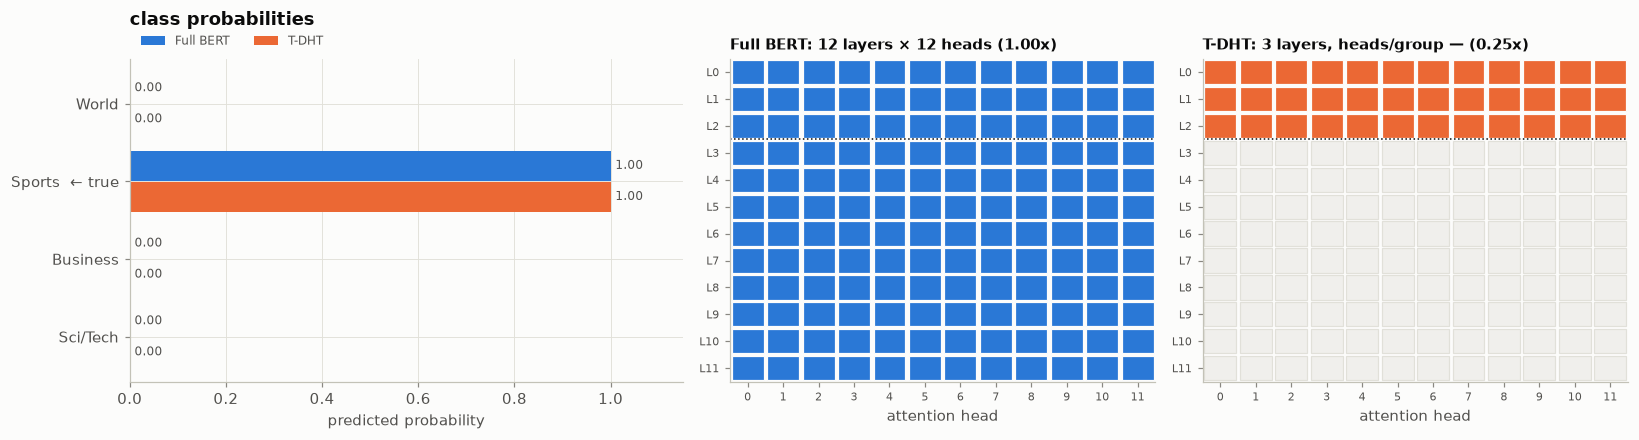

**4. Why DHT chose this path** (router scores; higher wins)

,depth UCB score,chosen
exit after 3 layers,+71.46,◀
exit after 6 layers,+24.55,
exit after 9 layers,+13.61,
exit after 12 layers,+0.74,


_Exited right after the 3-layer prefix, so no head decisions were needed._

**5. What if DHT had exited at a different depth?** (same DHT network, all heads)

,prediction,confidence,P(true class),compute,
exit,,,,,
3 layers,Sports,1.000,1.000,0.25x,◀ router's choice
6 layers,Sports,0.989,0.989,0.50x,
9 layers,Sports,0.979,0.979,0.75x,
12 layers,Sports,0.948,0.948,1.00x,


**6. Which words drove each prediction?**

Full BERT's top supporting words (margin drop): “Villa” (+0.52), “Aston” (+0.36), “to” (+0.27)
T-DHT's top supporting words (margin drop):     “derby.” (+0.63), “Villa” (+0.61), “overcoming” (+0.59)


In [27]:
walkthrough(joint.text[easy], int(joint.label[easy]))

### Example B — a harder headline that DHT sends through all 12 layers

Deep routes are rarer (3.4% of test samples) and concentrate on Business/Sci-Tech headlines. Notice
the head decisions: at each 3-layer group the count-UCB can still choose to thin the layer.

**2–3. Predictions and what each model computed**

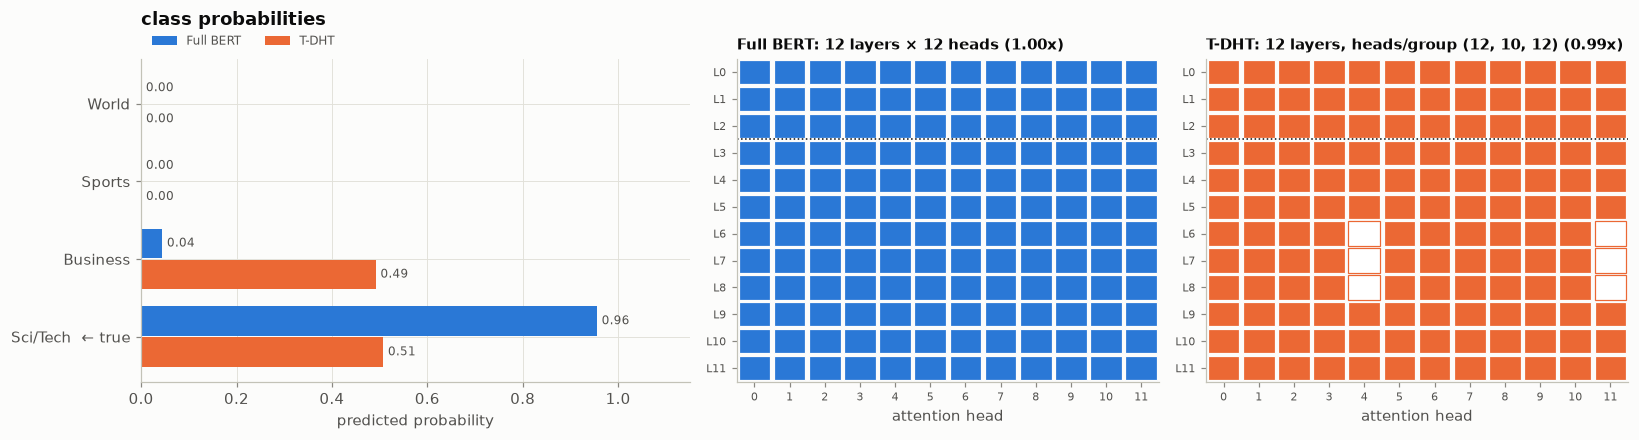

**4. Why DHT chose this path** (router scores; higher wins)

,depth UCB score,chosen
exit after 3 layers,-16.93,
exit after 6 layers,-10.84,
exit after 9 layers,-0.92,
exit after 12 layers,+0.02,◀


,score 8 heads,score 10 heads,score 12 heads,heads kept,heads dropped
layers,,,,,
3–5,-5.23,-7.39,2.47,12,none
6–8,-29.84,1.62,1.21,10,"4, 11"
9–11,-38.59,-18.24,3.45,12,none


**5. What if DHT had exited at a different depth?** (same DHT network, all heads)

,prediction,confidence,P(true class),compute,
exit,,,,,
3 layers,Sci/Tech,0.528,0.528,0.25x,
6 layers,Business,0.567,0.433,0.50x,
9 layers,Sci/Tech,0.515,0.515,0.75x,
12 layers,Sci/Tech,0.519,0.519,1.00x,◀ router's choice


**6. Which words drove each prediction?**

Full BERT's top supporting words (margin drop): “For” (+0.72), “price” (+0.64), “five-year,” (+0.61)
T-DHT's top supporting words (margin drop):     “officially” (+0.32), “\$1.” (-0.02), “IBM:” (-0.04)


In [28]:
walkthrough(joint.text[deep], int(joint.label[deep]))

### Example C — a router mistake: exiting early cost the right answer

Here full BERT is right and T-DHT is wrong, *and* step 5 shows that the same DHT network would have
been right had it gone deeper. The error is the router's, not the network's. This is the failure
mode behind most of DHT's lost accuracy.

**2–3. Predictions and what each model computed**

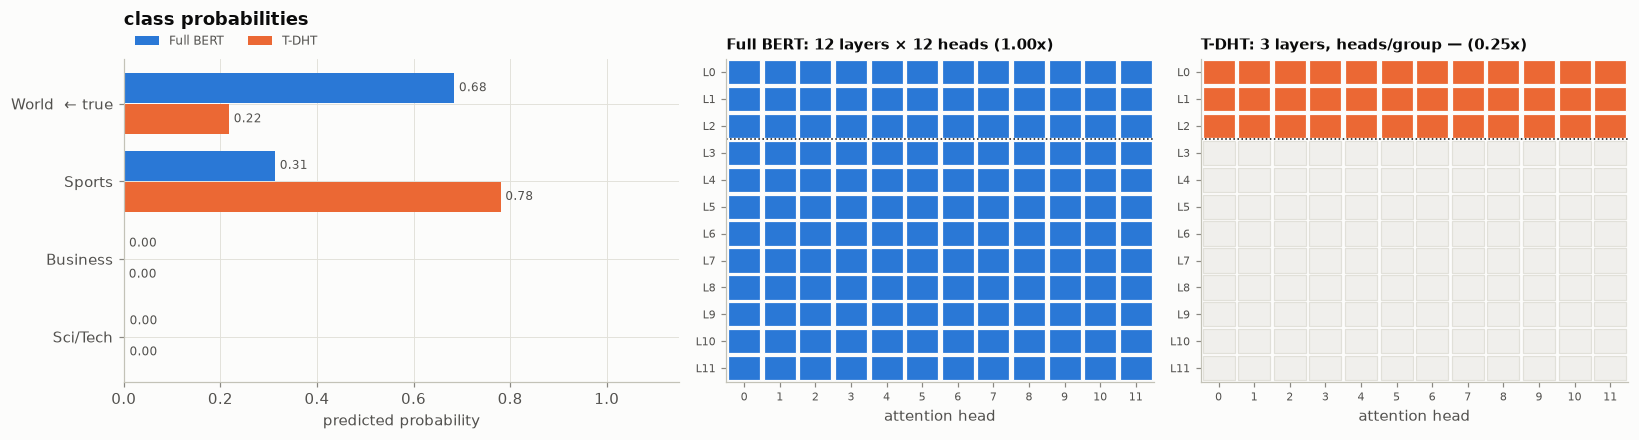

**4. Why DHT chose this path** (router scores; higher wins)

,depth UCB score,chosen
exit after 3 layers,+39.58,◀
exit after 6 layers,-2.04,
exit after 9 layers,+12.72,
exit after 12 layers,+0.36,


_Exited right after the 3-layer prefix, so no head decisions were needed._

**5. What if DHT had exited at a different depth?** (same DHT network, all heads)

,prediction,confidence,P(true class),compute,
exit,,,,,
3 layers,Sports,0.780,0.218,0.25x,◀ router's choice
6 layers,World,0.604,0.604,0.50x,
9 layers,World,0.740,0.740,0.75x,
12 layers,World,0.484,0.484,1.00x,


**6. Which words drove each prediction?**

Full BERT's top supporting words (margin drop): “Athens.” (+3.36), “Live:” (+2.79), “and” (+2.77)
T-DHT's top supporting words (margin drop):     “Parry” (+1.61), “going” (+0.39), “Stephen” (+0.19)


In [29]:
walkthrough(joint.text[router_mistake], int(joint.label[router_mistake]))

### Example D — DHT right, full BERT wrong

This happens less often (92 test samples vs 161 the other way). The two models are separately
trained networks, so they don't make identical mistakes.

**2–3. Predictions and what each model computed**

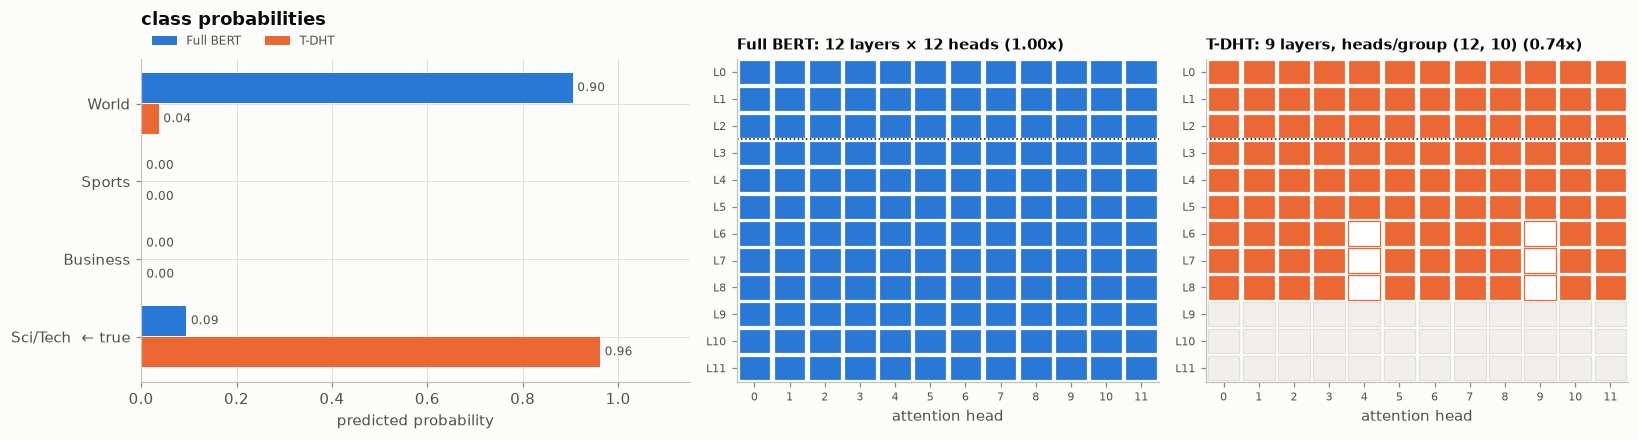

**4. Why DHT chose this path** (router scores; higher wins)

,depth UCB score,chosen
exit after 3 layers,-12.76,
exit after 6 layers,-19.24,
exit after 9 layers,+2.82,◀
exit after 12 layers,-0.01,


,score 8 heads,score 10 heads,score 12 heads,heads kept,heads dropped
layers,,,,,
3–5,-20.85,-3.93,2.12,12,none
6–8,-44.33,3.87,1.66,10,"4, 9"


**5. What if DHT had exited at a different depth?** (same DHT network, all heads)

,prediction,confidence,P(true class),compute,
exit,,,,,
3 layers,Sci/Tech,0.953,0.953,0.25x,
6 layers,Sci/Tech,0.928,0.928,0.50x,
9 layers,Sci/Tech,0.968,0.968,0.75x,◀ router's choice
12 layers,Sci/Tech,0.940,0.940,1.00x,


**6. Which words drove each prediction?**

Full BERT's top supporting words (margin drop): “AFP” (+10.27), “(AFP)” (+8.38), “Wireless,” (+3.57)
T-DHT's top supporting words (margin drop):     “Wireless” (+1.43), “AFP” (+1.06), “Wireless,” (+0.90)


In [30]:
walkthrough(joint.text[wins], int(joint.label[wins]))

### Example E — a made-up headline: "Yankees rally in the ninth to beat Red Sox 5-4"

Short headlines with no wire tag and no lede are unlike the training data. Watch step 5: the DHT
network predicts *World* at **every** exit, including all 12 layers. So this one is **not** a router
error. The DHT-trained network itself, whose shared classifier spends most of its training on
3-layer exits, learned different evidence from full BERT's. Step 6 shows which words each model
leaned on.

Try your own headline by editing the text in the cell.

**2–3. Predictions and what each model computed**

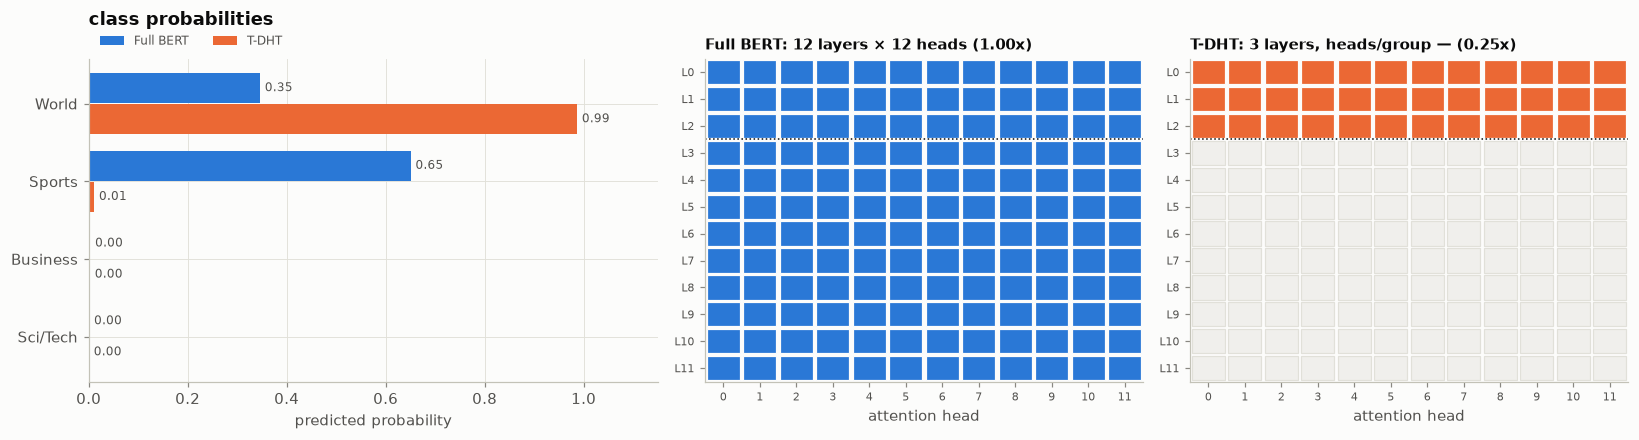

**4. Why DHT chose this path** (router scores; higher wins)

,depth UCB score,chosen
exit after 3 layers,+40.30,◀
exit after 6 layers,-15.33,
exit after 9 layers,+7.45,
exit after 12 layers,-0.03,


_Exited right after the 3-layer prefix, so no head decisions were needed._

**5. What if DHT had exited at a different depth?** (same DHT network, all heads)

,prediction,confidence,P(true class),compute,
exit,,,,,
3 layers,World,0.986,—,0.25x,◀ router's choice
6 layers,World,0.987,—,0.50x,
9 layers,World,0.981,—,0.75x,
12 layers,World,0.875,—,1.00x,


**6. Which words drove each prediction?**

Full BERT's top supporting words (margin drop): “ninth” (+0.53), “the” (+0.22), “in” (-0.10)
T-DHT's top supporting words (margin drop):     “Yankees” (+1.69), “Sox” (+1.67), “beat” (+1.54)


In [31]:
walkthrough("Yankees rally in the ninth to beat Red Sox 5-4")

## One *training* sentence across its three epochs

During training each of the 114,000 sentences is seen once per epoch, and **every visit is logged**:

- the architecture the router chose at that moment
- the sentence's loss
- the rewards it generated

The rewards follow the paper's ratio form, `reward = mean_previous_batch(loss × cost) / (loss × cost)`:

- `depth` is the reward for the depth choice (cost = layers).
- `head:3` / `head:6` / `head:9` are the rewards for each head group (cost = heads kept).
- A reward above 1 means "cheaper and/or lower loss than the previous batch average".
- Rewards are capped at 100. The paper-literal TS feedback labels a head set **1 when its reward is
  ≤ 1**, as printed on p.444.

Below are the first four sentences of the step-8,001 batch, tracked through all three epochs. At
the end, the *final* frozen model's decision for the same sentence is shown.

Training-time choices include the UCB **exploration bonus**; the frozen final policy uses only the
learned mean, so the two can differ for the same sentence.

In [32]:
first = json.loads((u.RUNS / u.EXPORTS["T-DHT"] / "metrics.jsonl").open().readline())
ids = [s["sample_id"] for s in first["samples"][:4]]
history = sa.training_history(set(ids))
for sid in ids:
    text, label = sa.train_text(sid)
    final_p, final_trace = sa.dht(text)
    display(
        HTML(
            f'<p style="margin-top:14px"><b>training sentence #{sid}</b> — true class <b>{u.AG_NEWS_CLASSES[label]}</b><br>'
            f"“{html.escape(text.replace(chr(92), ' ')[:220])}”</p>"
        )
    )
    table = pd.DataFrame(history[sid]).set_index("epoch")
    table["loss"] = table["loss"].map("{:.4f}".format)
    display(table)
    counts = tuple(g["head_count"] for g in final_trace["groups"])
    print(
        f"  final model today: {final_trace['total_depth']} layers, heads/group {counts or '—'}, predicts "
        f"{u.AG_NEWS_CLASSES[int(final_p.argmax())]} (p={float(final_p.max()):.3f})"
    )

,step,depth,heads/group,loss,rewards
epoch,,,,,
1,8001,9,8/10,0.0419,"{'depth': 12.707, 'head:3': 22.562, 'head:6': 14.951}"
2,22245,3,—,0.0158,{'depth': 24.341}
3,36497,3,—,0.0082,{'depth': 1.392}


  final model today: 3 layers, heads/group —, predicts Business (p=0.988)


,step,depth,heads/group,loss,rewards
epoch,,,,,
1,8001,9,10/10,0.0270,"{'depth': 19.748, 'head:3': 28.051, 'head:6': 23.235}"
2,22247,9,10/10,0.0145,"{'depth': 0.391, 'head:3': 0.47, 'head:6': 2.054}"
3,36498,9,10/10,0.0110,"{'depth': 0.172, 'head:3': 0.477, 'head:6': 3.719}"


  final model today: 3 layers, heads/group —, predicts Sci/Tech (p=0.997)


,step,depth,heads/group,loss,rewards
epoch,,,,,
1,8001,9,12/10,0.0168,"{'depth': 31.648, 'head:3': 37.462, 'head:6': 37.236}"
2,22245,3,—,0.0047,{'depth': 82.257}
3,36499,3,—,0.0041,{'depth': 15.067}


  final model today: 3 layers, heads/group —, predicts Sci/Tech (p=0.999)


,step,depth,heads/group,loss,rewards
epoch,,,,,
1,8001,9,10/10,0.0139,"{'depth': 38.348, 'head:3': 54.472, 'head:6': 45.119}"
2,22250,9,10/10,0.0066,"{'depth': 1.821, 'head:3': 10.531, 'head:6': 10.531}"
3,36505,9,10/10,0.0043,"{'depth': 1.801, 'head:3': 100.0, 'head:6': 100.0}"


  final model today: 3 layers, heads/group —, predicts Sci/Tech (p=0.982)


Following single sentences makes the averages concrete:

- **The route changes over training.** All four sentences were first trained through 9 layers with
  thinned heads. Two had moved to the 3-layer exit by epoch 2. The other two kept exploring 9-layer
  paths during training, but the final frozen policy sends **all four** out after 3 layers. As the
  network learns a sentence (loss ≈ 0.01), it becomes cheap.
- **The cap is visible.** One head reward sits exactly at 100 (the configured cap). This is the same
  clipping that happened 81,574 times over the run. With the paper-literal rule, head sets whose
  reward is ≤ 1 (e.g. 0.47) are labelled 1 for Thompson sampling.
- **Rewards are relative.** A sentence's reward depends on the *previous batch's* average
  loss × cost, so an identical choice can score 24 in one epoch and 1.4 in the next. This noisy,
  non-stationary signal is one reason the routing dynamics differ from the paper (see
  `docs/research/next_topics.md`, topic A1).
- **Per test sentence, DHT's errors come in two kinds.** Either the router exits too early (Example
  C: a deeper exit would have been right), or the DHT network itself disagrees with full BERT at
  every depth (Example E). The first can be fixed with better routing (e.g. a sequential RL exit
  policy). The second needs better training of the shared exits.

## Summary

**Datasets.** All four paper datasets are balanced, standard Zhang et al. (2015) corpora whose sizes
match the paper exactly.

- AG News and DBpedia are short, lexical topic tasks that a word-count model nearly solves.
  Those are ideal conditions for skipping depth.
- The Yelp corpora are long (often truncated at 300 tokens), sentiment-heavy, and (for Yelp Full)
  ordinal and noisy, with a hard ceiling around 0.66 F1.
- No exact duplicates or train/test leakage, but many escaped-text artifacts (HTML entities in
  ~30% of AG News rows, literal `\n` in ~55% of Yelp reviews) that affect every model equally.

**DHT vs no DHT (AG News, our runs).**

- T-DHT keeps ~99% of the fixed model's macro F1 while running ~39% of its task-path matmul FLOPs.
- It routes ~63% of test samples through only 3 layers. The depth it chooses does track sample
  difficulty and class (World/Sports shallow, Business/Sci-Tech deep), but imperfectly.
- Its errors come in two kinds (Part 3): the router exits too early on a hard sample (most
  often Business↔Sci/Tech), or the DHT network itself disagrees with full BERT at every exit (the
  made-up baseball headline is called *World* with p≈0.99 even after 12 layers).
- The routing trend over training is the *reverse* of the paper's Fig. 2.
- With the original per-sample execution the FLOP saving did **not** become wall-clock savings.
  The batched engine (D017) fixes that; timings are in notebook 02, section 9.

See `02_tree_vs_integrated_search.ipynb` for the integrated-search (F-DHT) comparison.